In [1]:
from sklearn import set_config
set_config(display="text")

# Day 05: Linear Regression and regression metrics.
# Run the cells from top to bottom.
# If an import fails, run this in a new cell once, then restart the kernel:
# %pip install "scikit-learn>=1.4" pandas matplotlib

In [2]:
# 1. Import pandas to read our data as a table.
import pandas as pd

In [3]:
# Import Matplotlib to draw charts.
import matplotlib.pyplot as plt

In [4]:
# Import the dataset loader. The data comes with scikit-learn.
from sklearn.datasets import load_diabetes

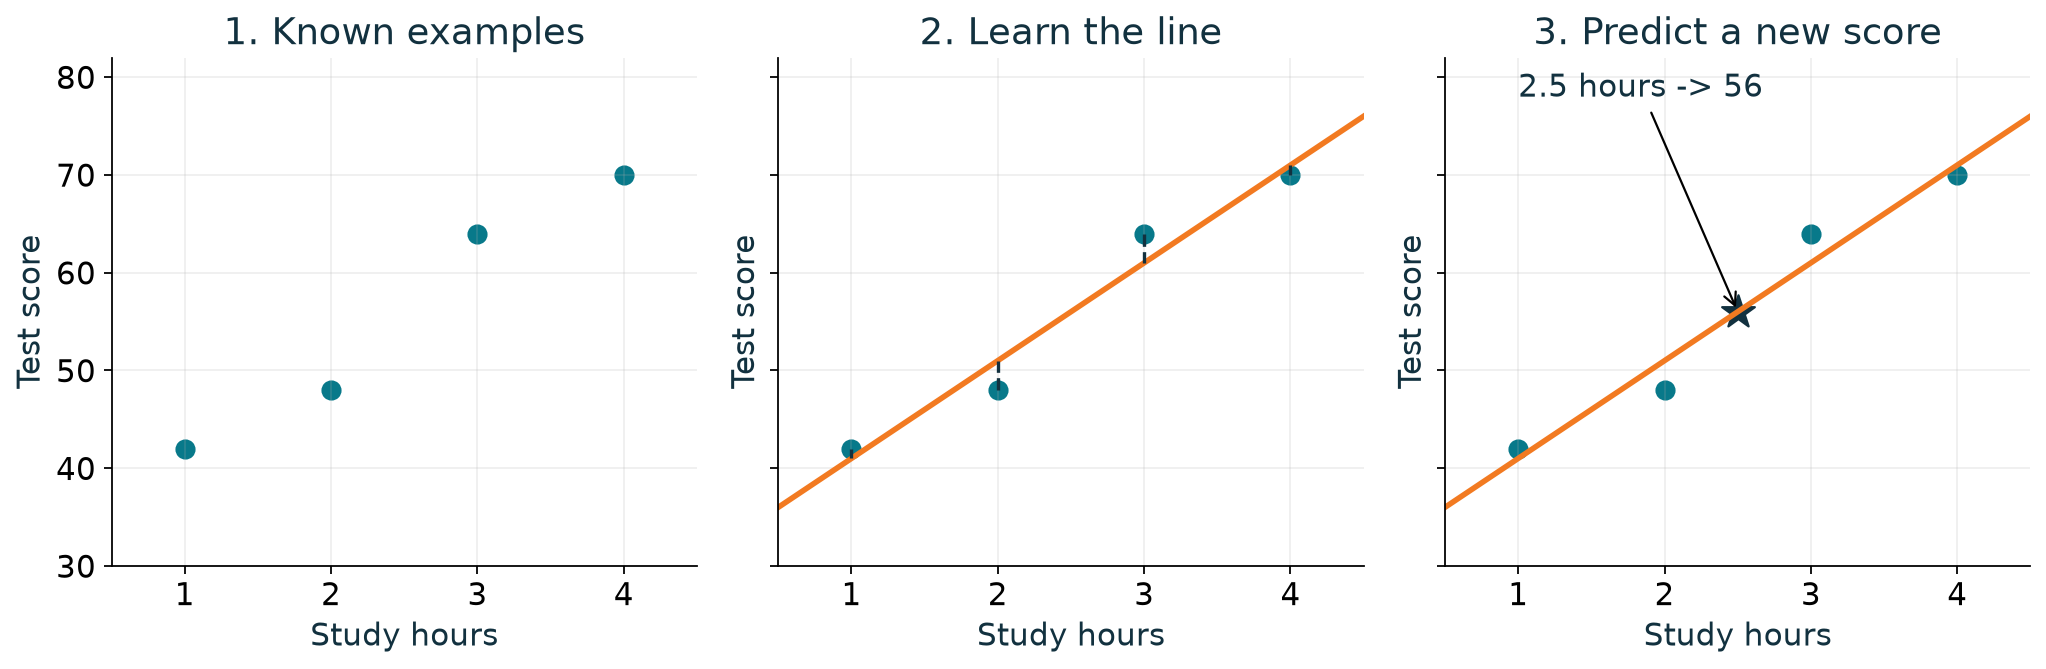

The line is learned from known scores. Dashed gaps are errors. The same fitted line predicts 56 for 2.5 study hours.

## Load the examples

A **dataset** is a set of records. Each record has input facts called **features** and a known answer called a **target**. The diabetes dataset contains measured disease progression scores. We use BMI as one input to keep the first model small. A **regression model** predicts a number.

In [5]:
# 2. Use raw inputs so BMI stays on its usual scale.
diabetes = load_diabetes(as_frame=True, scaled=False)

In [6]:
# Keep only one input so we can see the fitted line on a chart.
data = diabetes.frame[["bmi", "target"]].rename(columns={"target": "progression_score"}).copy()

In [7]:
# Each row is one person. The target is a disease-change score one year later.
data.head()

,bmi,progression_score
0,32.1,151.0
1,21.6,75.0
2,30.5,141.0
3,25.3,206.0
4,23.0,135.0


In [8]:
# Check how many rows and columns we have.
data.shape

(442, 2)

In [9]:
# Check that both columns hold numbers.
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bmi                442 non-null    float64
 1   progression_score  442 non-null    float64
dtypes: float64(2)
memory usage: 7.0 KB


In [10]:
# Count missing values. This dataset has none, so we do not fill or drop values.
data.isna().sum()

bmi                  0
progression_score    0
dtype: int64

In [11]:
# Check repeated rows. Equal measured values do not prove a row is a mistake.
data.duplicated().sum()

np.int64(2)

In [12]:
# See the ranges, average, and middle values.
data.describe().round(2)

,bmi,progression_score
count,442.00,442.00
mean,26.38,152.13
std,4.42,77.09
min,18.00,25.00
25%,23.20,87.00
50%,25.70,140.50
75%,29.28,211.50
max,42.20,346.00


In [13]:
# 3. X holds input columns. Double brackets keep a two-dimensional table.
X = data[["bmi"]]

In [14]:
# y holds the one answer column that the model will learn to predict.
y = data["progression_score"]

In [15]:
# Import the split tool before we use it.
from sklearn.model_selection import train_test_split

## Keep some records for a fair check

**Training records** teach the model. **Test records** are kept out of training and used to check predictions. `train_test_split()` divides inputs and their matching targets together. `test_size=0.2` sets aside about 20%. `random_state=42` fixes the shuffle so this example can be repeated. If `stratify=y` is used, it keeps the class shares close to those in the full dataset.

In [16]:
# Keep 20% for testing. Seed 42 keeps this lesson's split the same on each run.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
# Confirm the training and test sizes.
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 353 | Test rows: 89


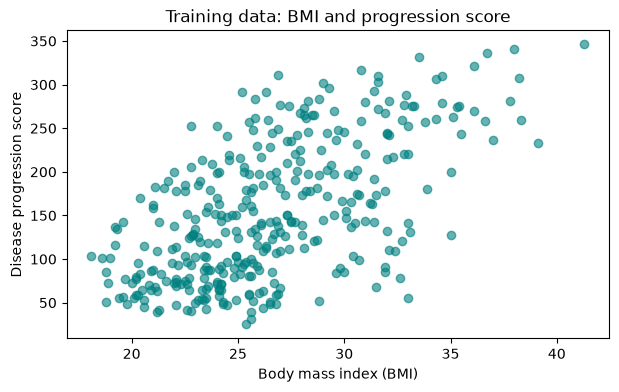

In [18]:
# 4. EDA: inspect training data. The test answers stay out of our choices.
plt.figure(figsize=(7, 4))
plt.scatter(X_train["bmi"], y_train, color="teal", alpha=0.6)
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression score")
plt.title("Training data: BMI and progression score")
plt.show()

In [19]:
# A rising pattern is visible, but the wide spread means BMI cannot explain every score.
print("Training correlation:", round(X_train["bmi"].corr(y_train), 2))

Training correlation: 0.6


In [20]:
# Import the model class before creating the model.
from sklearn.linear_model import LinearRegression

## Create and fit the model

**LinearRegression** learns a slope and intercept for a straight line. A prediction follows that same fitted rule for a new input.

Creating the model sets up its settings. `fit()` supplies the training examples.

In [21]:
# 5. Create a model. We use one feature and the default fitting method.
model = LinearRegression()

In [22]:
# fit() learns the model values using inputs X_train and known answers y_train.
# fit learns the slope and intercept from training rows only.
model.fit(X_train, y_train)

LinearRegression()

In [23]:
# Inspect the two learned values.
print("Slope:", round(model.coef_[0], 2), "| Intercept:", round(model.intercept_, 2))

Slope: 10.76 | Intercept: -131.87


In [24]:
# Sort BMI values so the fitted line is drawn from left to right.
line_X = X_train.sort_values("bmi")

In [25]:
# predict() uses the trained model. Test answers are not given to it.
# Use the learned model to get a predicted score for each value on the line.
line_y = model.predict(line_X)

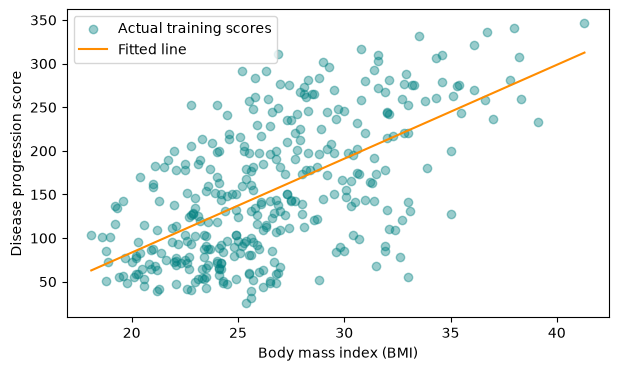

In [26]:
# The line shows the model. The dots show the real training scores.
plt.figure(figsize=(7, 4))
plt.scatter(X_train["bmi"], y_train, alpha=0.4, color="teal", label="Actual training scores")
plt.plot(line_X["bmi"], line_y, color="darkorange", label="Fitted line")
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression score")
plt.legend()
plt.show()

In [27]:
# predict() uses the trained model. Test answers are not given to it.
# 6. Now predict the held-out test rows. No test answers are passed to predict.
y_pred = model.predict(X_test)

In [28]:
# Put actual and predicted answers side by side for the same test rows.
results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred}).round(1)

In [29]:
# A residual is actual minus predicted.
results["Residual"] = results["Actual"] - results["Predicted"]

In [30]:
# Check the first five test predictions.
results.head()

,Actual,Predicted,Residual
287,219.0,145.8,73.2
211,70.0,188.9,-118.9
72,202.0,148.0,54.0
321,230.0,203.9,26.1
73,111.0,131.8,-20.8


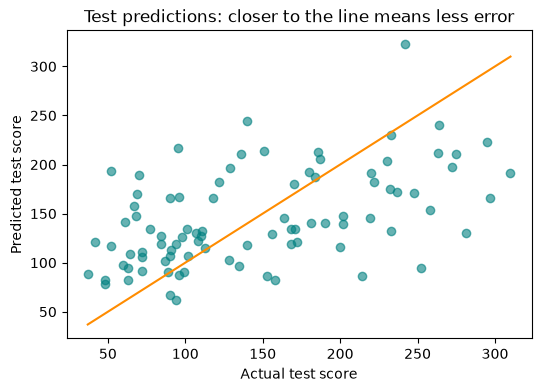

In [31]:
# On this chart, a perfect prediction would sit on the orange line.
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, color="teal", alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="darkorange")
plt.xlabel("Actual test score")
plt.ylabel("Predicted test score")
plt.title("Test predictions: closer to the line means less error")
plt.show()

In [32]:
# Import the regression metrics. Regression does not use classification accuracy.
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

## Measure the test predictions

**MAE** is the mean absolute error in target units. **MSE** is the mean squared error. **RMSE** returns the error to the original units and gives large errors more weight. **R-squared** compares the model with a mean-value guess; it is not classification accuracy.

In [33]:
# 7. MAE: average error size, in score points. Lower is better.
mae = mean_absolute_error(y_test, y_pred)

In [34]:
# MSE: average squared error. It gives more weight to large mistakes.
mse = mean_squared_error(y_test, y_pred)

In [35]:
# RMSE: square root of MSE, back in score points. Lower is better.
rmse = root_mean_squared_error(y_test, y_pred)

In [36]:
# R-squared: compares squared errors with the test-target mean. Higher is better.
r2 = r2_score(y_test, y_pred)

In [37]:
# Show all four final test metrics.
pd.Series({"MAE (points)": mae, "MSE (points squared)": mse, "RMSE (points)": rmse, "R-squared": r2}).round(3)

MAE (points)              52.260
MSE (points squared)    4061.826
RMSE (points)             63.732
R-squared                  0.233
dtype: float64